#Decoding Phone Usage Patterns in India

In [1]:
# import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
#import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [2]:
#Datacleaning
# Load data
df = pd.read_csv("phone_usage_india.csv")

In [3]:
#understaing data
df.head()

,User ID,Age,Gender,Location,Phone Brand,OS,Screen Time (hrs/day),Data Usage (GB/month),Calls Duration (mins/day),Number of Apps Installed,Social Media Time (hrs/day),E-commerce Spend (INR/month),Streaming Time (hrs/day),Gaming Time (hrs/day),Monthly Recharge Cost (INR),Primary Use
0,U00001,53,Male,Mumbai,Vivo,Android,3.7,23.9,37.9,104,3.9,469,5.2,4.1,803,Education
1,U00002,60,Other,Delhi,Realme,iOS,9.2,28.1,13.7,169,2.8,4997,5.1,0.4,1526,Gaming
2,U00003,37,Female,Ahmedabad,Nokia,Android,4.5,12.3,66.8,96,3.0,2381,1.7,2.9,1619,Entertainment
3,U00004,32,Male,Pune,Samsung,Android,11.0,25.6,156.2,146,5.2,1185,3.2,0.3,1560,Entertainment
4,U00005,16,Male,Mumbai,Xiaomi,iOS,2.2,2.5,236.2,86,5.5,106,3.4,2.3,742,Social Media


In [4]:
df.shape

(17686, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17686 entries, 0 to 17685
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   User ID                       17686 non-null  object 
 1   Age                           17686 non-null  int64  
 2   Gender                        17686 non-null  object 
 3   Location                      17686 non-null  object 
 4   Phone Brand                   17686 non-null  object 
 5   OS                            17686 non-null  object 
 6   Screen Time (hrs/day)         17686 non-null  float64
 7   Data Usage (GB/month)         17686 non-null  float64
 8   Calls Duration (mins/day)     17686 non-null  float64
 9   Number of Apps Installed      17686 non-null  int64  
 10  Social Media Time (hrs/day)   17686 non-null  float64
 11  E-commerce Spend (INR/month)  17686 non-null  int64  
 12  Streaming Time (hrs/day)      17686 non-null  float64
 13  G

In [6]:
df.describe()

,Age,Screen Time (hrs/day),Data Usage (GB/month),Calls Duration (mins/day),Number of Apps Installed,Social Media Time (hrs/day),E-commerce Spend (INR/month),Streaming Time (hrs/day),Gaming Time (hrs/day),Monthly Recharge Cost (INR)
count,17686.000000,17686.000000,17686.000000,17686.000000,17686.000000,17686.000000,17686.000000,17686.000000,17686.000000,17686.000000
mean,37.584247,6.546376,25.411257,151.405846,104.584869,3.252369,5075.707848,4.250616,2.490874,1042.785367
std,13.338252,3.172677,14.122167,84.923353,55.217097,1.590223,2871.604841,2.155683,1.446003,552.502067
min,15.000000,1.000000,1.000000,5.000000,10.000000,0.500000,100.000000,0.500000,0.000000,100.000000
25%,26.000000,3.800000,13.200000,77.325000,57.000000,1.900000,2587.500000,2.400000,1.200000,561.000000
50%,38.000000,6.600000,25.300000,150.600000,104.000000,3.200000,5052.000000,4.200000,2.500000,1040.000000
75%,49.000000,9.300000,37.600000,223.900000,152.000000,4.600000,7606.000000,6.100000,3.700000,1521.750000
max,60.000000,12.000000,50.000000,300.000000,200.000000,6.000000,10000.000000,8.000000,5.000000,2000.000000


In [7]:
df.isnull().sum()

User ID                         0
Age                             0
Gender                          0
Location                        0
Phone Brand                     0
OS                              0
Screen Time (hrs/day)           0
Data Usage (GB/month)           0
Calls Duration (mins/day)       0
Number of Apps Installed        0
Social Media Time (hrs/day)     0
E-commerce Spend (INR/month)    0
Streaming Time (hrs/day)        0
Gaming Time (hrs/day)           0
Monthly Recharge Cost (INR)     0
Primary Use                     0
dtype: int64

In [8]:
df.duplicated().sum()

0

In [9]:
#checking for identical ids
df["User ID"].duplicated().sum()

0

In [10]:
df["Primary Use"].value_counts()

Primary Use
Education        3601
Gaming           3576
Work             3557
Social Media     3501
Entertainment    3451
Name: count, dtype: int64

In [11]:
# Drop unnecessary columns
df.drop(['User ID'], axis=1, inplace=True)

In [12]:
#Unique & Categorical Insights
df.columns

Index(['Age', 'Gender', 'Location', 'Phone Brand', 'OS',
       'Screen Time (hrs/day)', 'Data Usage (GB/month)',
       'Calls Duration (mins/day)', 'Number of Apps Installed',
       'Social Media Time (hrs/day)', 'E-commerce Spend (INR/month)',
       'Streaming Time (hrs/day)', 'Gaming Time (hrs/day)',
       'Monthly Recharge Cost (INR)', 'Primary Use'],
      dtype='object')

In [ ]:
for col in df.columns:
  print(f"{col}:\n Unique values:",df[col].nunique(),"\n", df[col].unique())
  print()
  print()

Age:
 Unique values: 46 
 [53 60 37 32 16 21 57 56 46 44 55 41 35 33 52 54 50 40 59 29 36 15 51 45
 39 28 23 20 22 19 49 42 17 31 43 25 34 38 30 18 24 26 58 27 48 47]


Gender:
 Unique values: 3 
 ['Male' 'Other' 'Female']


Location:
 Unique values: 10 
 ['Mumbai' 'Delhi' 'Ahmedabad' 'Pune' 'Jaipur' 'Lucknow' 'Kolkata'
 'Bangalore' 'Chennai' 'Hyderabad']


Phone Brand:
 Unique values: 10 
 ['Vivo' 'Realme' 'Nokia' 'Samsung' 'Xiaomi' 'Oppo' 'Apple' 'Google Pixel'
 'Motorola' 'OnePlus']


OS:
 Unique values: 2 
 ['Android' 'iOS']


Screen Time (hrs/day):
 Unique values: 111 
 [ 3.7  9.2  4.5 11.   2.2  5.4  6.   3.1  5.3  9.9  1.6  7.5 10.5 10.3
  1.7  5.1 11.6  9.  10.4 11.7  8.1  1.4  7.   5.6 10.7  6.3  4.   8.4
 11.4  4.1  9.4 11.9  5.5  5.2  2.5  4.4  4.2  4.3  1.5  4.7  8.6  5.8
  3.4  3.   3.5  1.3  3.2  8.3 11.2  6.9  6.8  6.1 11.1  5.7  1.8 10.
  5.   2.4  8.8  6.7 10.9 10.8  2.3  7.2 11.8  8.   7.8  3.6  4.8  7.9
  9.3  9.6  1.2  8.5  8.9  5.9 10.1  6.5  2.9  7.7  8.2  1.1  3.

In [15]:
numeric_df = df.select_dtypes(include="number")
numeric_cols =numeric_df.columns

In [16]:
numeric_cols

Index(['Age', 'Screen Time (hrs/day)', 'Data Usage (GB/month)',
       'Calls Duration (mins/day)', 'Number of Apps Installed',
       'Social Media Time (hrs/day)', 'E-commerce Spend (INR/month)',
       'Streaming Time (hrs/day)', 'Gaming Time (hrs/day)',
       'Monthly Recharge Cost (INR)'],
      dtype='object')

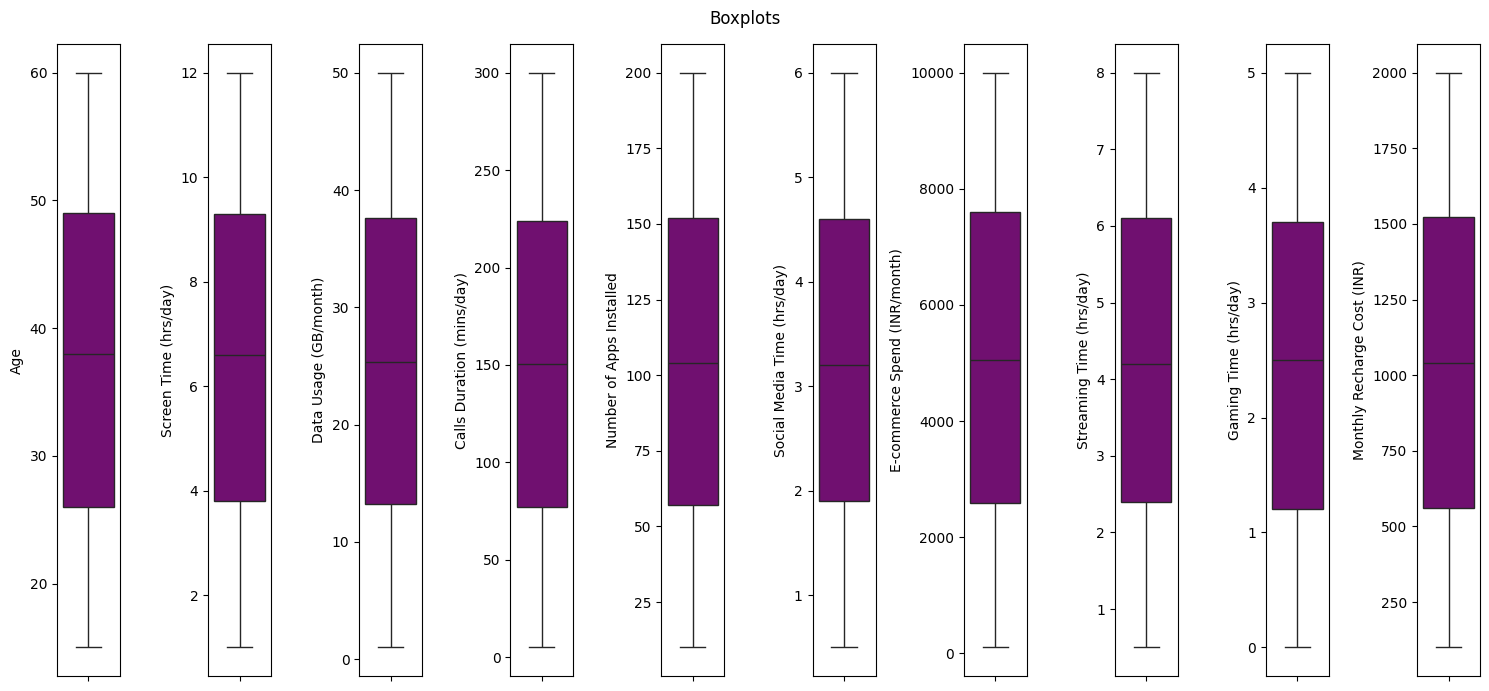

In [17]:
plt.figure(figsize=(15, 7))
plt.suptitle("Boxplots")
for i in range(0, len(numeric_cols)):
    plt.subplot(1, 10, i+1)
    sns.boxplot(y=df[numeric_cols[i]],color='purple',)
    plt.tight_layout()

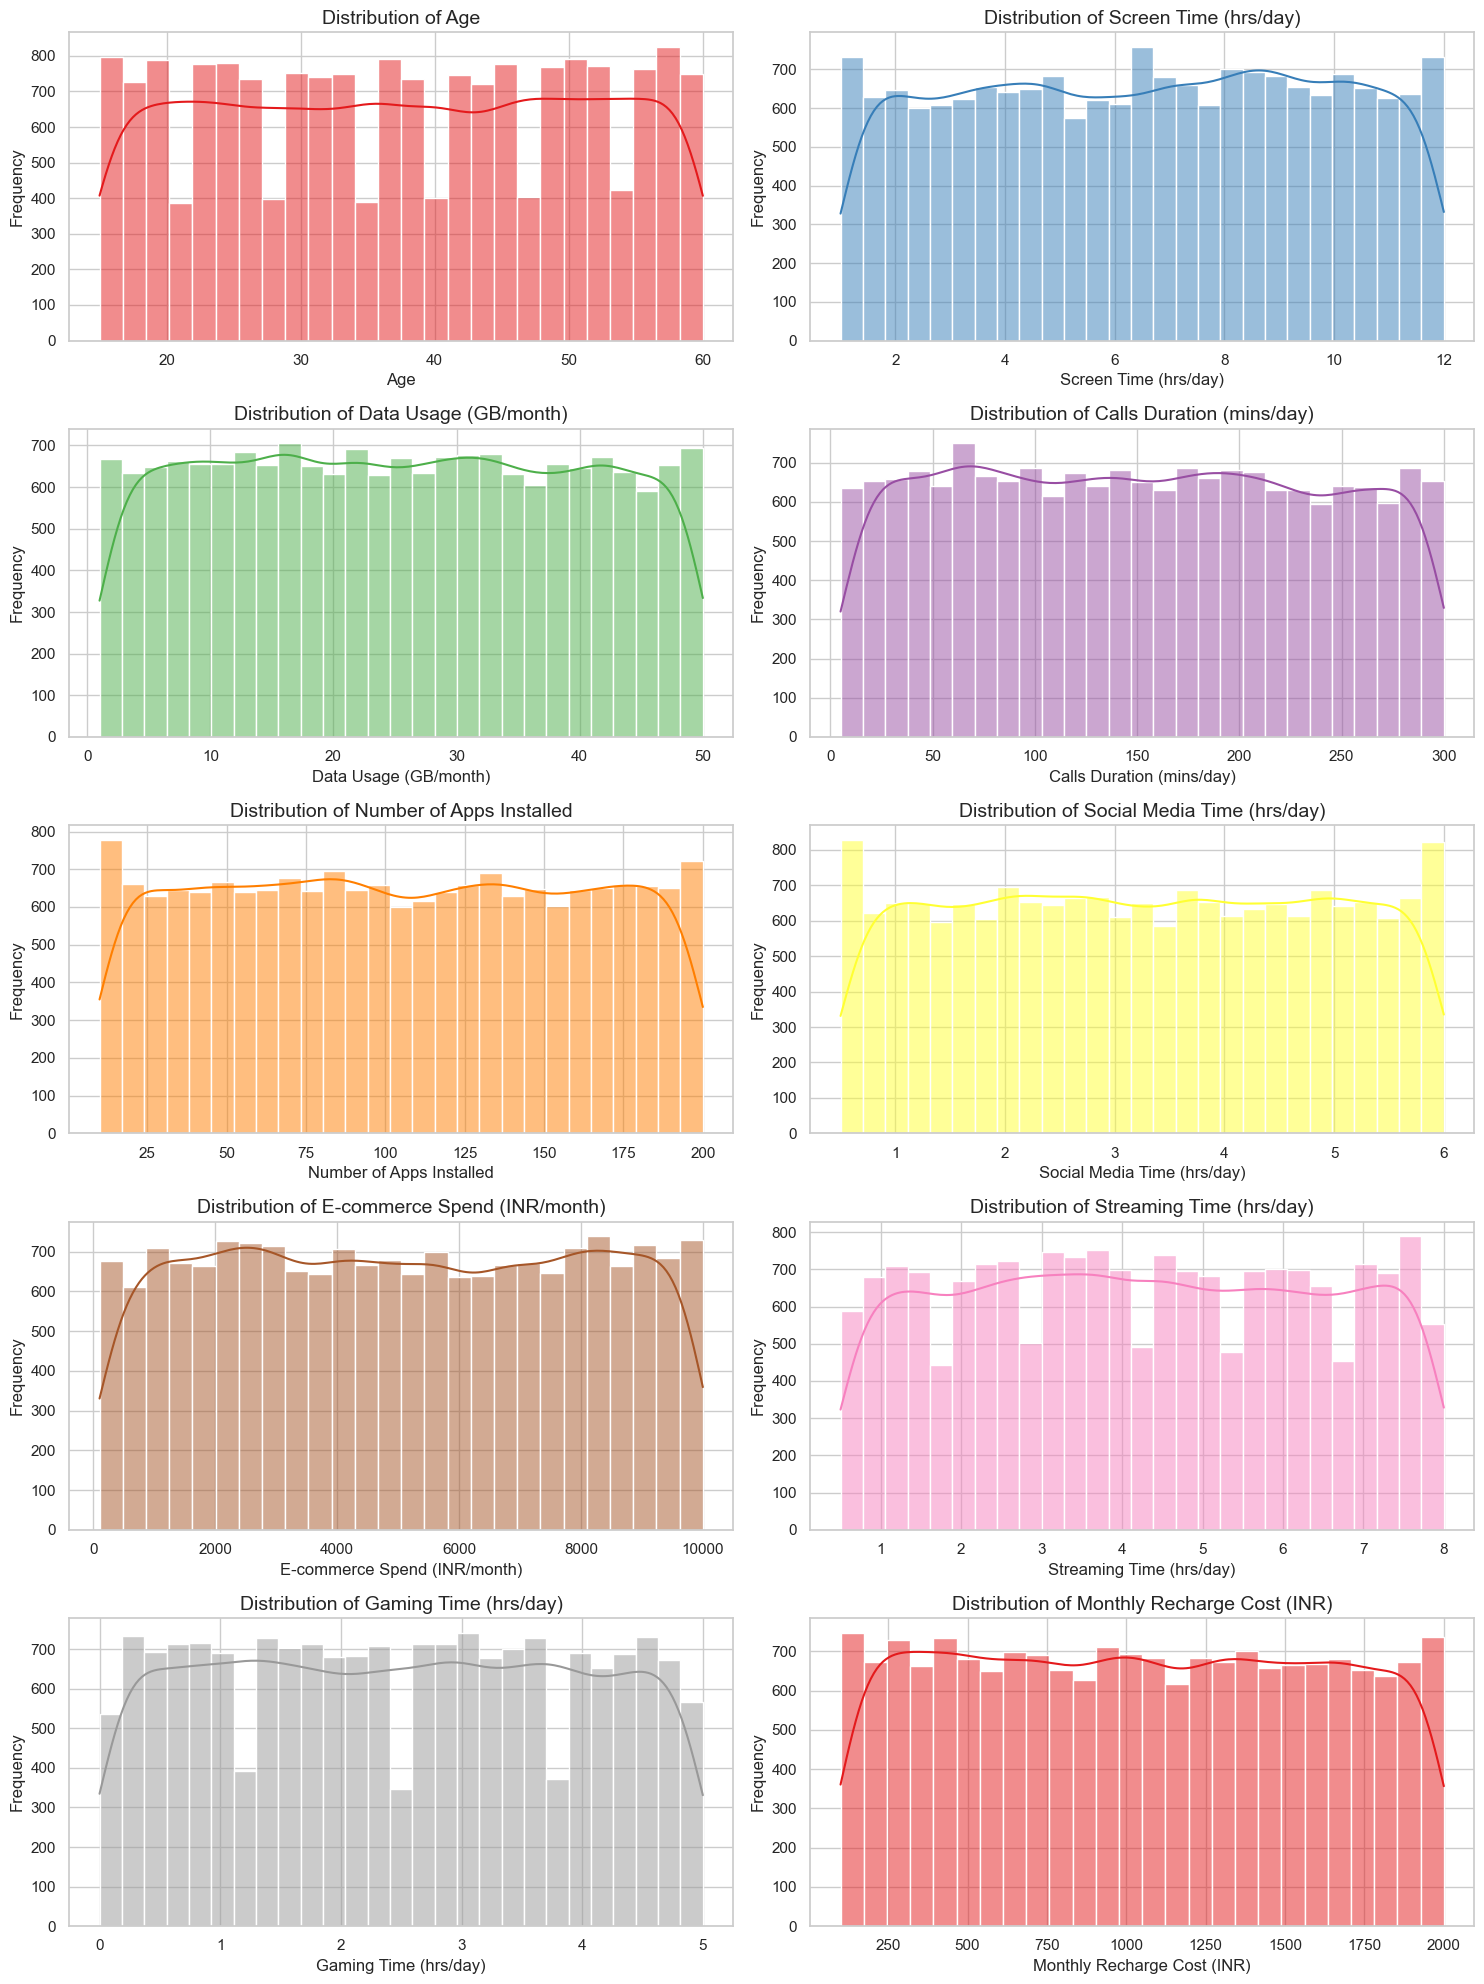

In [ ]:
#EDA
# Distribution of Numeric Variables
#sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 20))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, color=sns.color_palette("Set1", len(numeric_cols))[i], ax=axes[i])
    axes[i].set_title(f"Distribution of {col}", fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel("Frequency", fontsize=12)

plt.tight_layout()
#plt.savefig('Distribution.png')
plt.show()

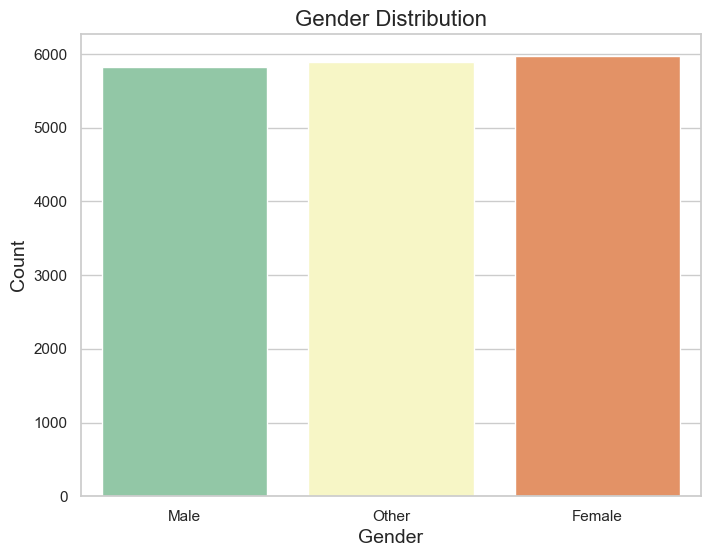

In [ ]:
#explore categorical data
# Gender Distribution
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x="Gender", hue='Gender', palette="Spectral_r")
plt.title("Gender Distribution", fontsize=16)
plt.xlabel("Gender", fontsize=14)
plt.ylabel("Count", fontsize=14)
plt.savefig('Gender Distribution.png')
plt.show()

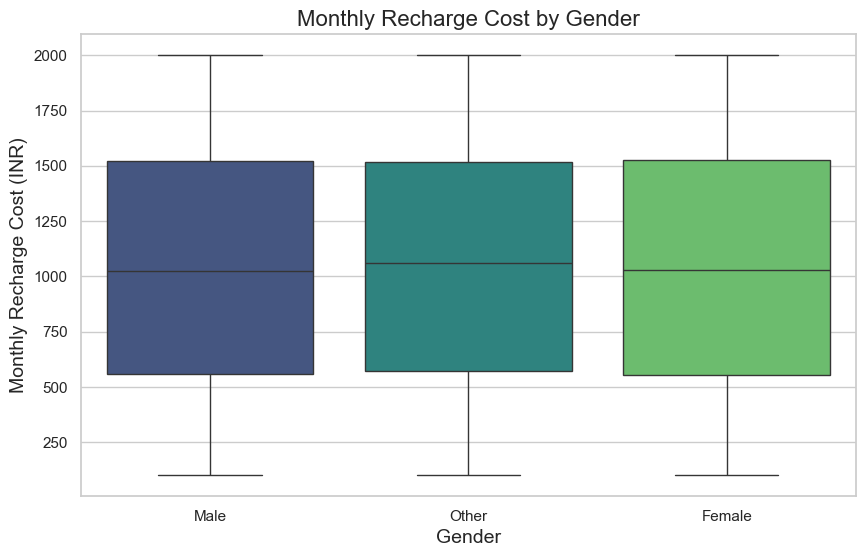

In [22]:
# Gender vs. Monthly Recharge Cost
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Gender", y="Monthly Recharge Cost (INR)", hue='Gender', palette="viridis")
plt.title("Monthly Recharge Cost by Gender", fontsize=16)
plt.xlabel("Gender", fontsize=14)
plt.ylabel("Monthly Recharge Cost (INR)", fontsize=14)
#plt.savefig('Monthly Recharge Cost by Gender.png'
plt.show()

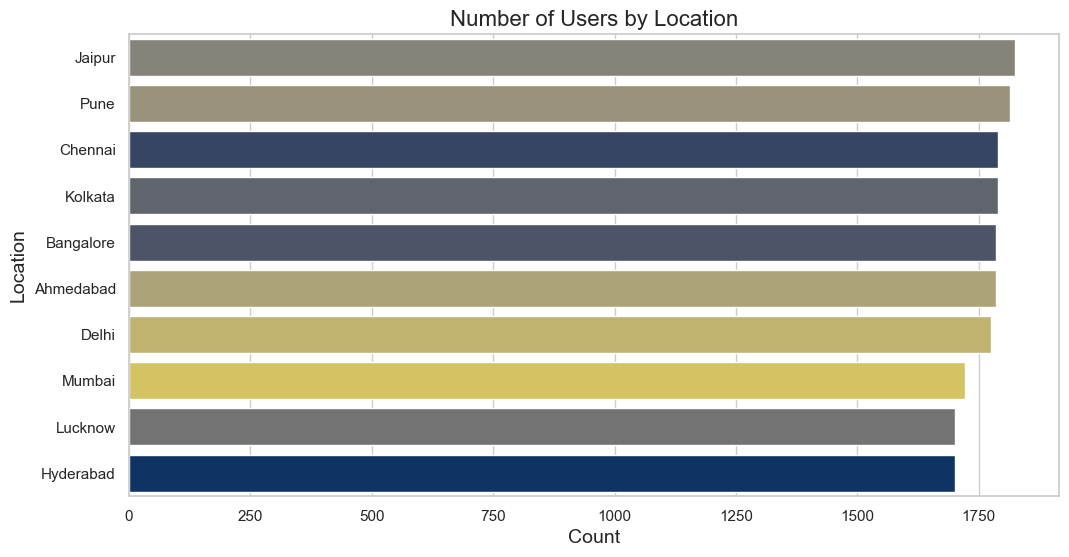

In [ ]:
# Location-wise Analysis
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y="Location", hue='Location', order=df["Location"].value_counts().index, palette="cividis_r")
plt.title("Number of Users by Location", fontsize=16)
plt.xlabel("Count", fontsize=14)
plt.ylabel("Location", fontsize=14)
#plt.savefig('Number of Users by Location.png')
plt.show()

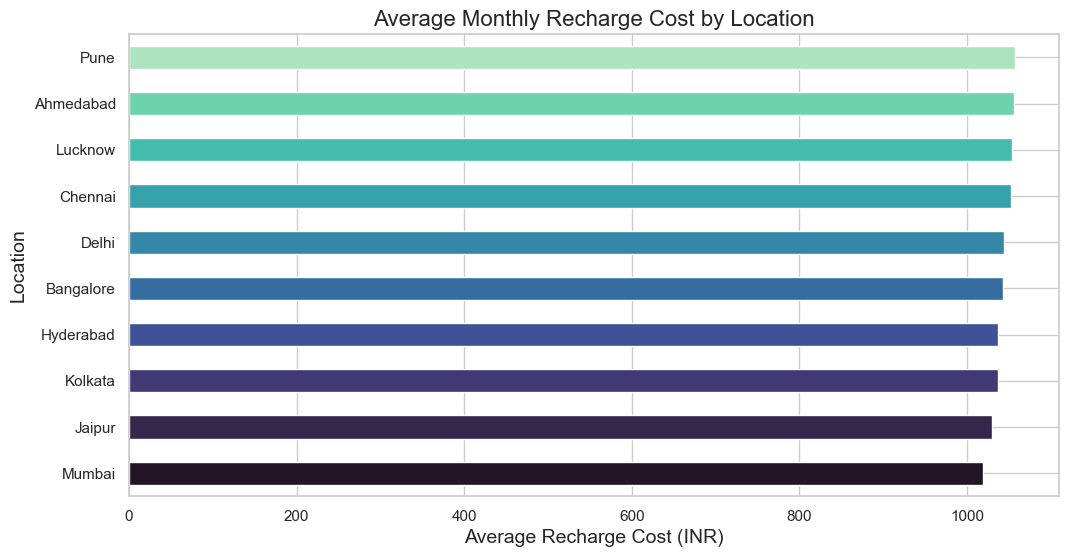

In [26]:
# Average Monthly Recharge Cost by Location
location_recharge = df.groupby("Location")["Monthly Recharge Cost (INR)"].mean().sort_values()

plt.figure(figsize=(12, 6))
location_recharge.plot(kind="barh", color=sns.color_palette("mako", len(location_recharge)))
plt.title("Average Monthly Recharge Cost by Location", fontsize=16)
plt.xlabel("Average Recharge Cost (INR)", fontsize=14)
plt.ylabel("Location", fontsize=14)
#plt.savefig('Average Monthly Recharge Cost by Location.png')
plt.show()

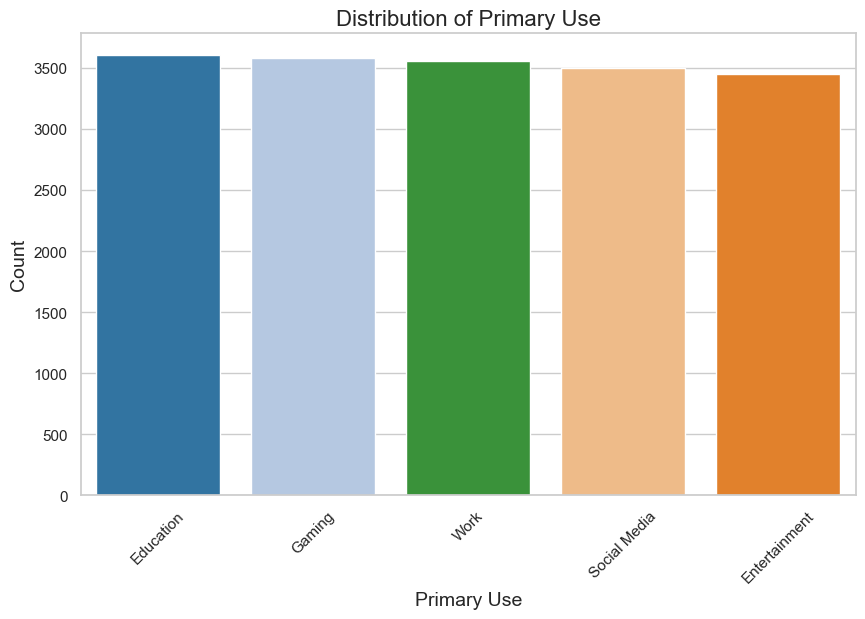

In [27]:
# Primary Use Analysis
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Primary Use", hue='Primary Use', order=df["Primary Use"].value_counts().index, palette="tab20")
plt.title("Distribution of Primary Use", fontsize=16)
plt.xlabel("Primary Use", fontsize=14)
plt.ylabel("Count", fontsize=14)
plt.xticks(rotation=45)
#plt.savefig('Distribution of Primary Use.png')
plt.show()

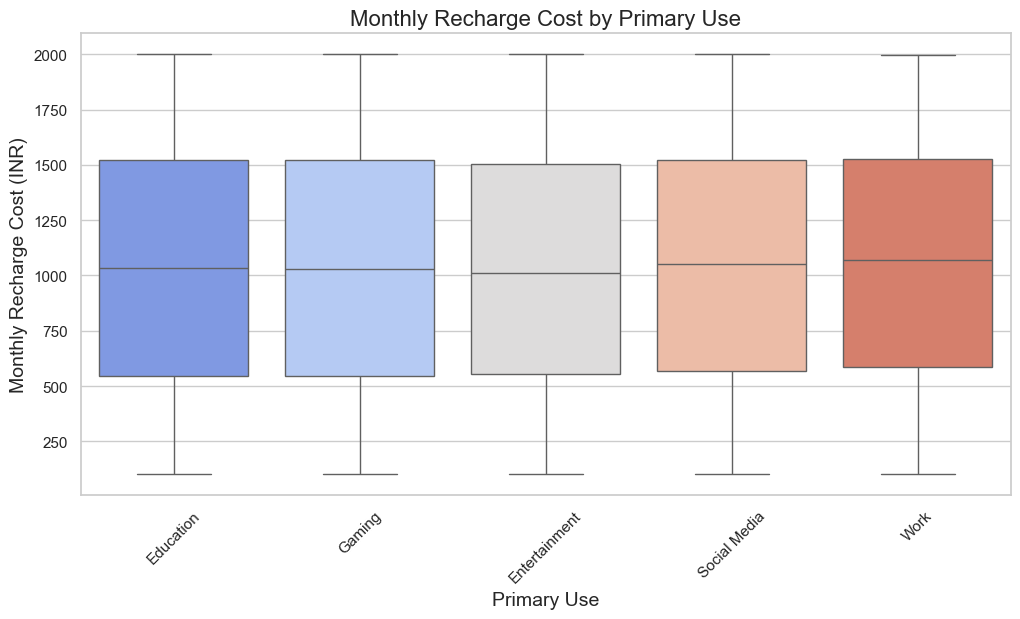

In [28]:
# Monthly Recharge Cost by Primary Use
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Primary Use", hue='Primary Use', y="Monthly Recharge Cost (INR)", palette="coolwarm")
plt.title("Monthly Recharge Cost by Primary Use", fontsize=16)
plt.xlabel("Primary Use", fontsize=14)
plt.ylabel("Monthly Recharge Cost (INR)", fontsize=14)
plt.xticks(rotation=45)
plt.show()

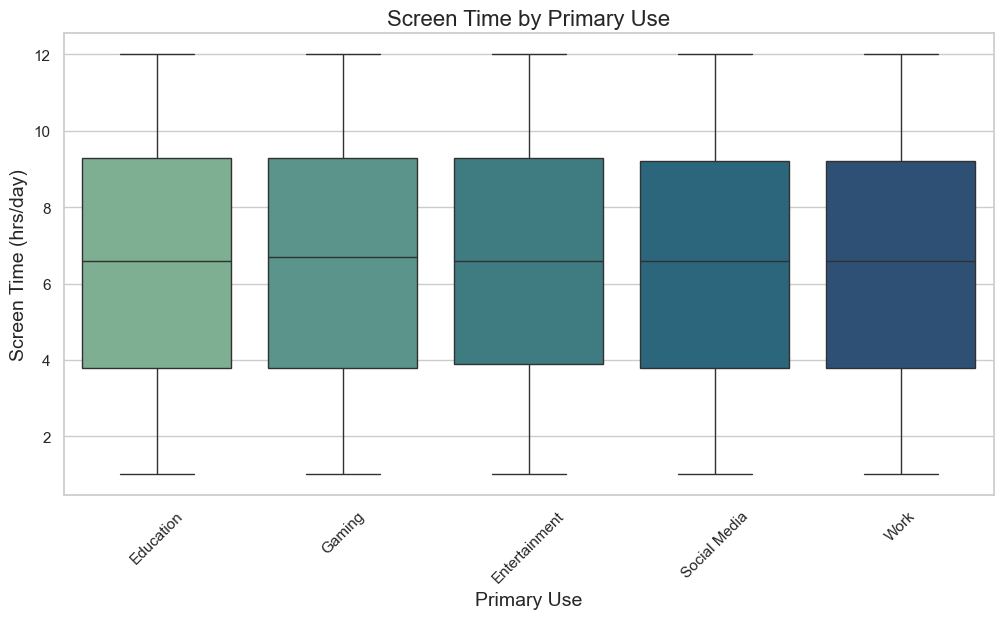

In [29]:
# Screen Time by Primary Use
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Primary Use", y="Screen Time (hrs/day)", hue='Primary Use', palette="crest")
plt.title("Screen Time by Primary Use", fontsize=16)
plt.xlabel("Primary Use", fontsize=14)
plt.ylabel("Screen Time (hrs/day)", fontsize=14)
plt.xticks(rotation=45)
#plt.savefig('Screen Time by Primary Use.png')
plt.show()


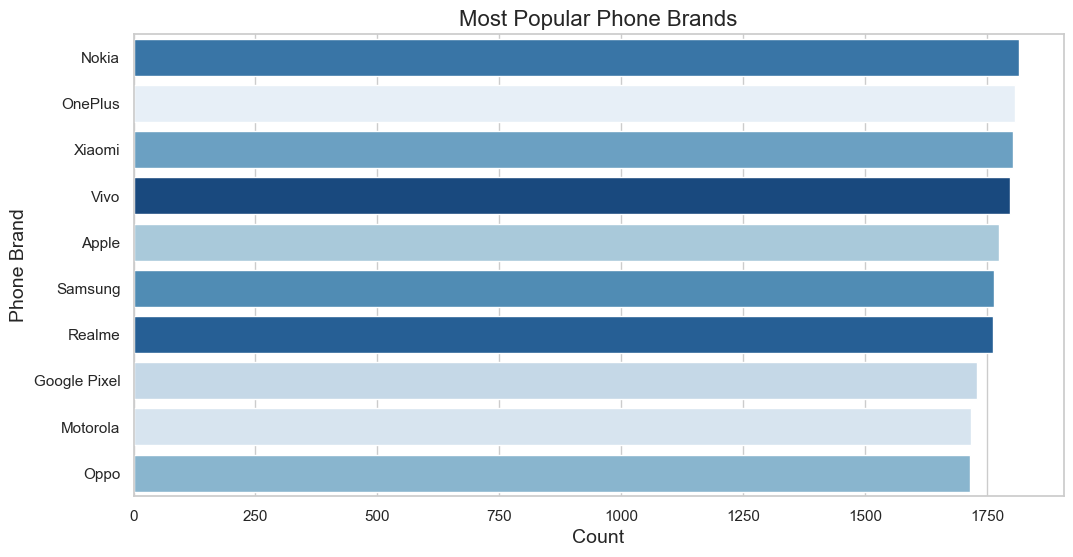

In [32]:
# Most popular Phone Brand 
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y="Phone Brand", hue="Phone Brand", order=df["Phone Brand"].value_counts().index, palette="Blues_r")
plt.title("Most Popular Phone Brands", fontsize=16)
plt.xlabel("Count", fontsize=14)
plt.ylabel("Phone Brand", fontsize=14)
#plt.savefig('Most Popular Phone Brands.png')
plt.show()

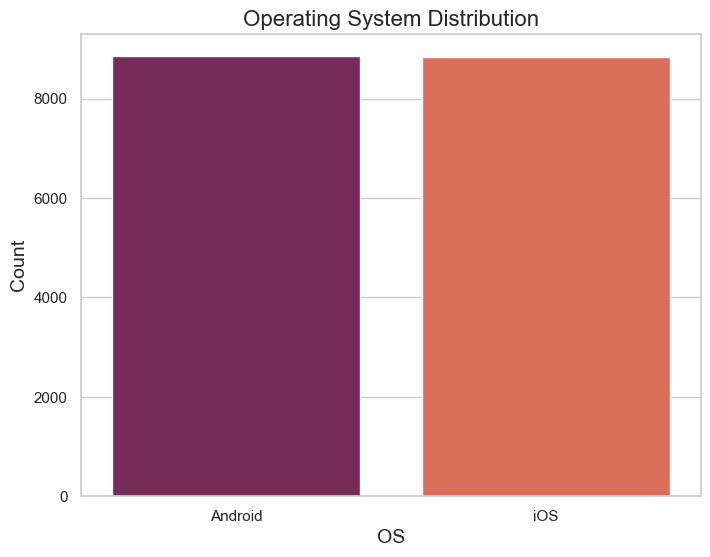

In [33]:
# OS Distribution
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x="OS", hue="OS", palette="rocket")
plt.title("Operating System Distribution", fontsize=16)
plt.xlabel("OS", fontsize=14)
plt.ylabel("Count", fontsize=14)
#plt.savefig('Operating System Distribution.png')
plt.show()

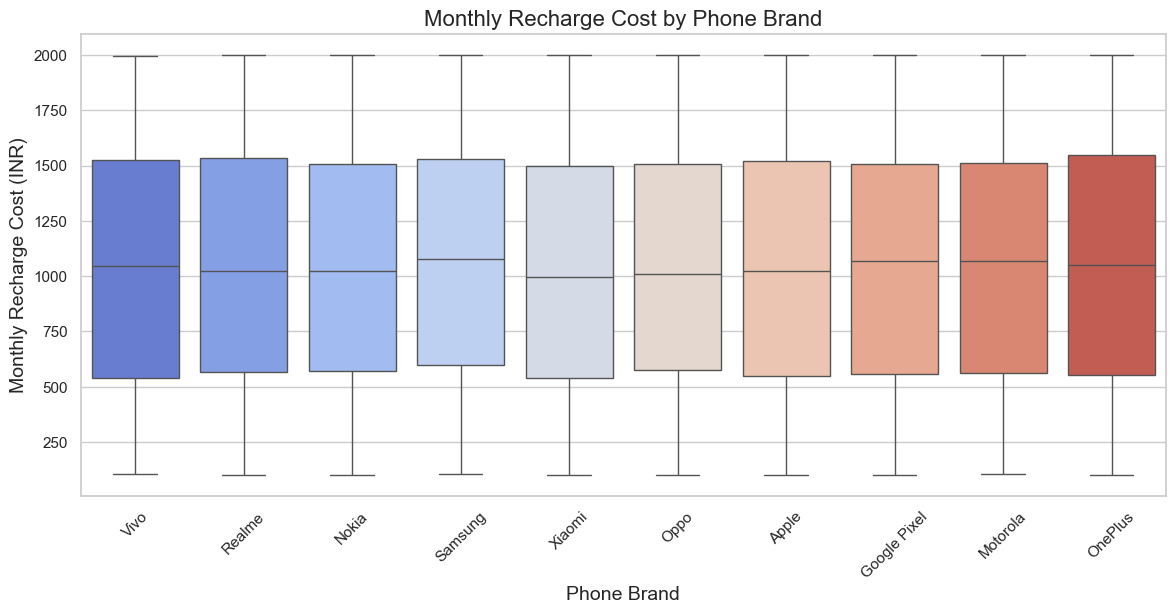

In [34]:
# Monthly Recharge Cost by Phone Brand
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="Phone Brand", hue="Phone Brand", y="Monthly Recharge Cost (INR)", palette="coolwarm")
plt.title("Monthly Recharge Cost by Phone Brand", fontsize=16)
plt.xlabel("Phone Brand", fontsize=14)
plt.ylabel("Monthly Recharge Cost (INR)", fontsize=14)
plt.xticks(rotation=45)
#plt.savefig('Monthly Recharge Cost by Phone Brand.png')
plt.show()

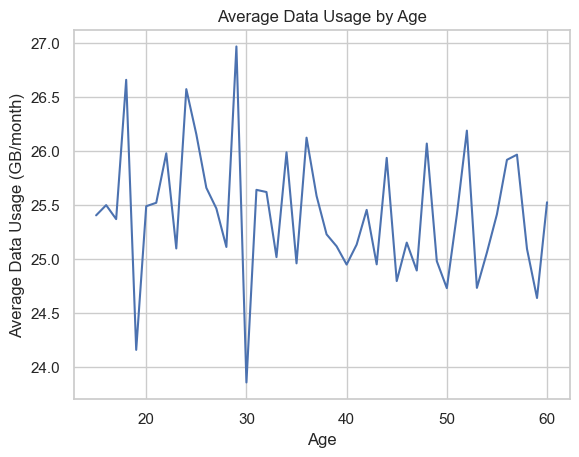

In [44]:
#a scatter plot puts thousands of individual points on the same graph, so it can look like a cloud of dots.so trying below plot
df.groupby("Age")["Data Usage (GB/month)"].mean().plot(kind="line")

plt.title("Average Data Usage by Age")
plt.xlabel("Age")
plt.ylabel("Average Data Usage (GB/month)")
plt.show()

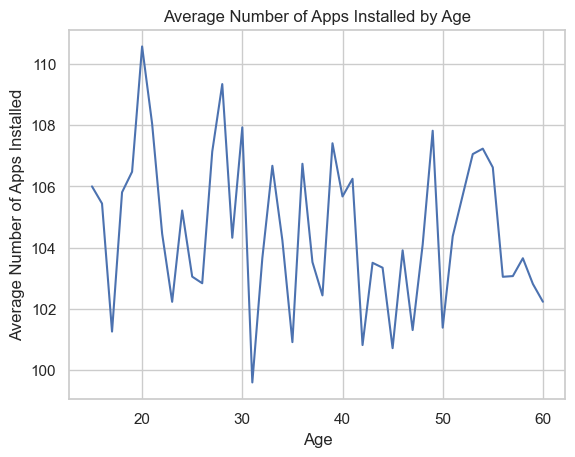

In [45]:
#age versus number of apps installed.
df.groupby("Age")["Number of Apps Installed"].mean().plot(kind="line")

plt.title("Average Number of Apps Installed by Age")
plt.xlabel("Age")
plt.ylabel("Average Number of Apps Installed")
plt.show()

In [46]:
df.groupby("Primary Use")[
    [
        "Screen Time (hrs/day)",
        "Data Usage (GB/month)",
        "Calls Duration (mins/day)",
        "Social Media Time (hrs/day)",
        "Streaming Time (hrs/day)",
        "Gaming Time (hrs/day)"
    ]
].mean()

,Screen Time (hrs/day),Data Usage (GB/month),Calls Duration (mins/day),Social Media Time (hrs/day),Streaming Time (hrs/day),Gaming Time (hrs/day)
Primary Use,,,,,,
Education,6.530741,25.375312,152.901305,3.230880,4.235490,2.458595
Entertainment,6.595653,25.583918,151.759809,3.301101,4.279021,2.540249
Gaming,6.568205,25.329614,151.093037,3.236270,4.271141,2.494491
Social Media,6.501885,25.410226,150.183290,3.252756,4.259469,2.482891
Work,6.536238,25.363227,151.066264,3.242648,4.209024,2.479871


In [ ]:
# Compute correlation matrix
corr_matrix = df[numeric_cols].corr()
#corr_matrix

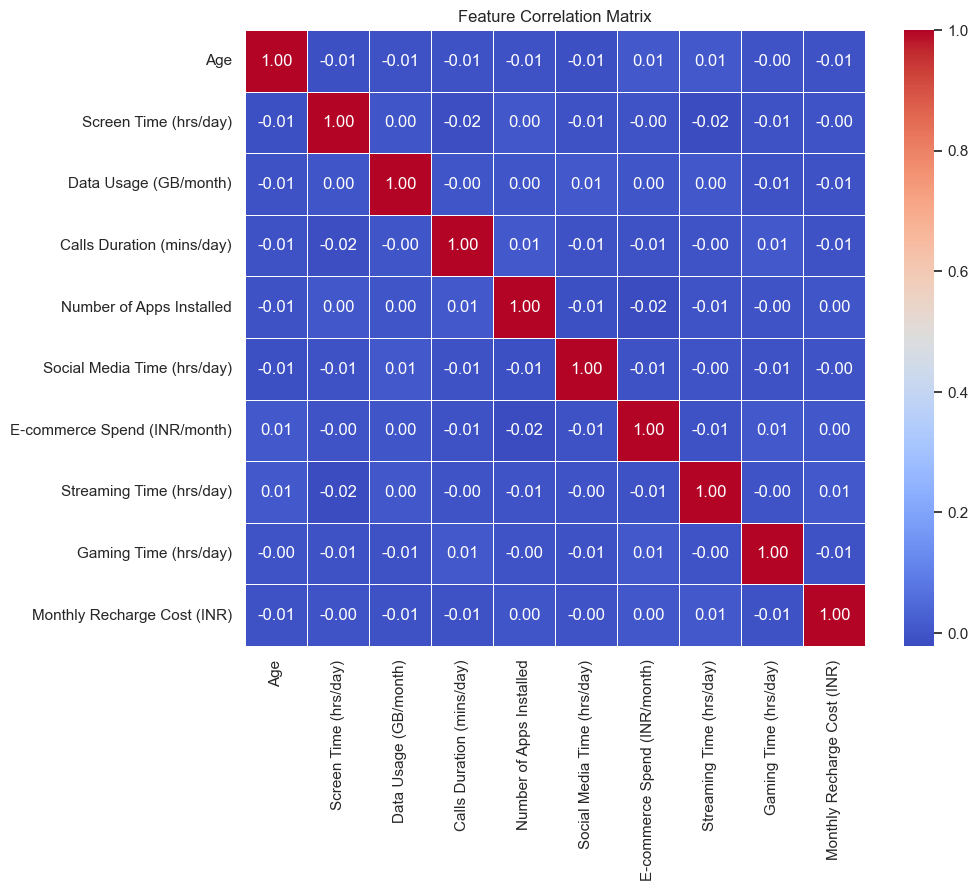

In [39]:
# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Matrix")
#plt.savefig('Feature Correlation Matrix.png')
plt.show()

Feature Engineering

In [40]:
df[[
    "Screen Time (hrs/day)",
    "Social Media Time (hrs/day)",
    "Streaming Time (hrs/day)",
    "Gaming Time (hrs/day)"
]].head()

,Screen Time (hrs/day),Social Media Time (hrs/day),Streaming Time (hrs/day),Gaming Time (hrs/day)
0,3.7,3.9,5.2,4.1
1,9.2,2.8,5.1,0.4
2,4.5,3.0,1.7,2.9
3,11.0,5.2,3.2,0.3
4,2.2,5.5,3.4,2.3


In [41]:
# Create Entertainment Index: average of streaming, gaming, and social media
df["Entertainment_Index"] = (
    df["Streaming Time (hrs/day)"] +
    df["Gaming Time (hrs/day)"] +
    df["Social Media Time (hrs/day)"]
) / 3

In [42]:
# Create Spend Ratio: E-commerce Spend vs. Recharge Cost
df["Spend_Ratio"] = df["E-commerce Spend (INR/month)"] / (df["Monthly Recharge Cost (INR)"] + 1)

In [43]:
df.head()

,Age,Gender,Location,Phone Brand,OS,Screen Time (hrs/day),Data Usage (GB/month),Calls Duration (mins/day),Number of Apps Installed,Social Media Time (hrs/day),E-commerce Spend (INR/month),Streaming Time (hrs/day),Gaming Time (hrs/day),Monthly Recharge Cost (INR),Primary Use,Entertainment_Index,Spend_Ratio
0,53,Male,Mumbai,Vivo,Android,3.7,23.9,37.9,104,3.9,469,5.2,4.1,803,Education,4.400000,0.583333
1,60,Other,Delhi,Realme,iOS,9.2,28.1,13.7,169,2.8,4997,5.1,0.4,1526,Gaming,2.766667,3.272430
2,37,Female,Ahmedabad,Nokia,Android,4.5,12.3,66.8,96,3.0,2381,1.7,2.9,1619,Entertainment,2.533333,1.469753
3,32,Male,Pune,Samsung,Android,11.0,25.6,156.2,146,5.2,1185,3.2,0.3,1560,Entertainment,2.900000,0.759129
4,16,Male,Mumbai,Xiaomi,iOS,2.2,2.5,236.2,86,5.5,106,3.4,2.3,742,Social Media,3.733333,0.142665


In [47]:
df[["Entertainment_Index", "Spend_Ratio"]].isna().sum()

Entertainment_Index    0
Spend_Ratio            0
dtype: int64

In [48]:
import numpy as np

np.isinf(df[["Entertainment_Index", "Spend_Ratio"]]).sum()

Entertainment_Index    0
Spend_Ratio            0
dtype: int64

In [49]:
df.to_csv("phone_usage_feature_engineered.csv", index=False)

In [50]:
df.shape

(17686, 17)

In [51]:
df.columns

Index(['Age', 'Gender', 'Location', 'Phone Brand', 'OS',
       'Screen Time (hrs/day)', 'Data Usage (GB/month)',
       'Calls Duration (mins/day)', 'Number of Apps Installed',
       'Social Media Time (hrs/day)', 'E-commerce Spend (INR/month)',
       'Streaming Time (hrs/day)', 'Gaming Time (hrs/day)',
       'Monthly Recharge Cost (INR)', 'Primary Use', 'Entertainment_Index',
       'Spend_Ratio'],
      dtype='object')